# AST 326: Exoplanet Transits
### Tutorial 2B - Differential Photometry to Standardize Images 
- Primary Authors: Jacob Taylor, Bethany Ludwig
- Last Revision: February 2024
  
### Overview of the Lab:  

The goal of this lab is to detect an exoplanet and measure its properties. 

The overall schedule for this lab is as follows: 

1) Reduce your data, source detection, image motion, aperture photometry (Feb 5)

2) Brightness corrections (differential photometry), create a light curve (Feb 12)

3) Reading week (Feb 19)
  
4) Model our light curve to determine exoplanet properties (Feb 26)

5) Open work session (March 4) 

6) Report Due (March 11)  
  
### This Week:  
In the last notebook we found astrometric corrections for the stars in the image. We also generated a light curve for one of those stars.  
  
Now we will apply that process to a bunch of "standard stars" so we can correct for the brightness variations we saw in the last notebook.  
  
This lab will be in two parts:  
  
A. Generate the photometry for a bunch of standard stars  
B. Create a differential light curve so we can standardize the brightness in each image  

posx and posy should be finite values
posx and posy should be finite values
posx and posy should be finite values


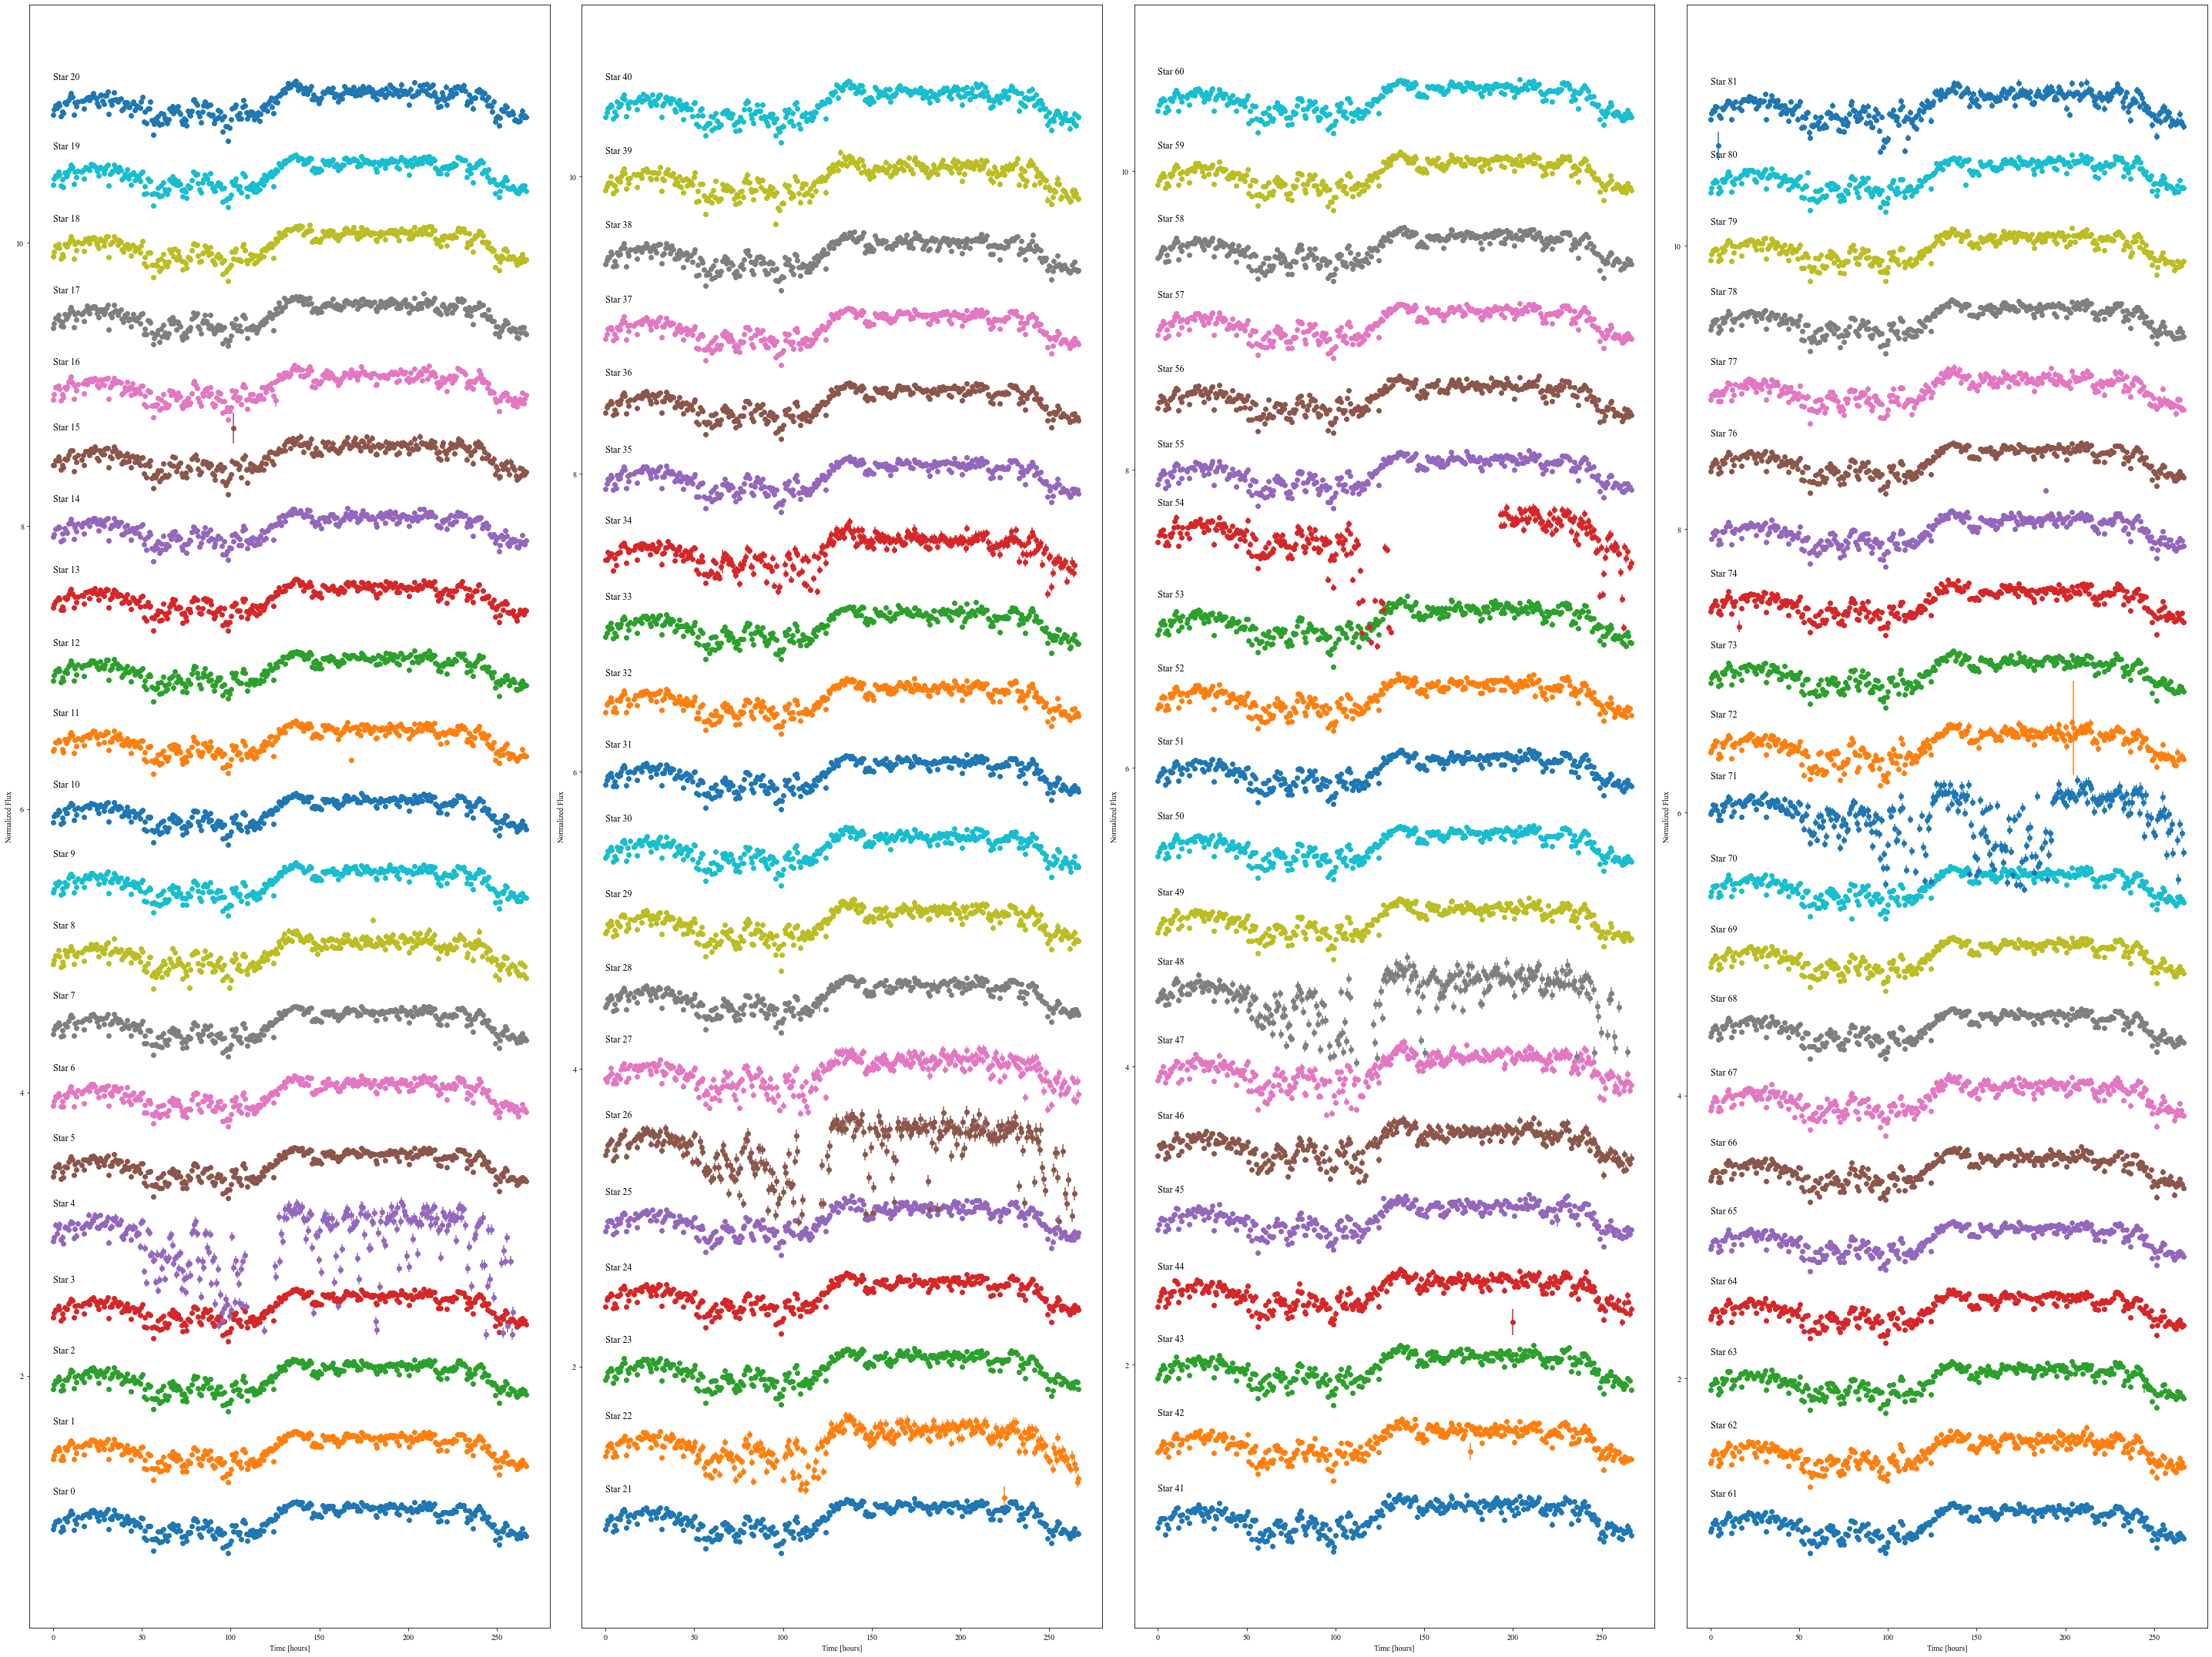

In [1]:
from astropy.io import fits
from astropy.visualization import ZScaleInterval
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd 
import glob,sys
sys.path.append('Lib/')
import ta_funcs_transit as ta
# Set matplotlib font to be publication quality
# If this gives you issues just comment it out
plt.rcParams["font.family"] = "Times New Roman"
plt.rcParams["font.serif"] = "Computer Modern Roman"

# If you saved your photometry for each star to a seperate file read it in now 



# Plot your normalized light curves, add in an artifical offset in y to make them easier to see 


# Key thing to notice, is that al lthe light curves have the same dent in them.
# This is due to the brightness variations in the images and it's something we want to account for.

In [2]:
# We want the most well behaved light curves to use as a reference so remove any that look messed up 
remove_index = []
all_index = np.arange(len( ... ))
good_index = [i for i in all_index if i not in remove_index]

# You can also look at them a bit closer to be sure.
# I set this up as a widget to make it easier to look through them quickly.
# If you're having trouble getting it to work don't worry about it, 
# You could still use the plot_lc function below if you want to. 
import ipywidgets as widgets

def plot_lc(index):
    index = good_index[index]
    plt.figure(figsize=(10,5))
    plt.errorbar(phot[index].time,phot[index].flux,yerr=phot[index].flux_err,fmt='o')
    plt.xlabel('Time [hours]',fontsize=18)
    plt.ylabel('Normalized Flux',fontsize=18)
    plt.title(f'Light Curve of Star {index}',fontsize=20)
    plt.tick_params(labelsize=15);

w = widgets.IntSlider()
widgets.interact(plot_lc,index=w)

# Don't forget to pay attention to the y-axis

interactive(children=(IntSlider(value=0, description='index'), Output()), _dom_classes=('widget-interact',))

<function __main__.plot_lc(index)>

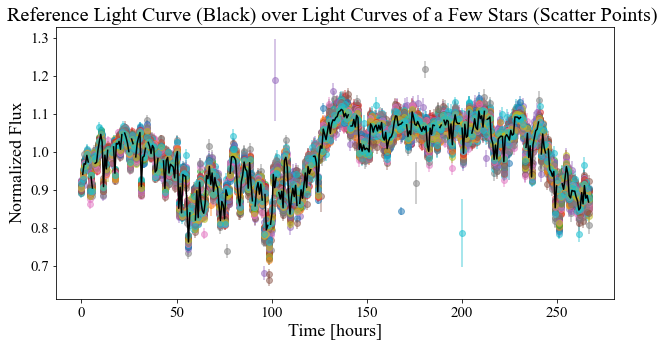

In [3]:
# Now that we have our good light curves, we can use them to create a reference light curve


# You could take the median:
# reference_lc = np.nanmean(reference_phot,axis=0)

# But if you've accounted for outliers you could also use this which lets you put in weights
weights = 1./(reference_phot_err**2)
reference_lc = np.average(reference_phot, weights=weights,axis=0)

# Third option, if you experience issues with the above two methods, you can use this function
# def nanaverage(arr, weights, axis=0):
#     # Convert nans to 0s
#     nan_mask = np.isnan(weights*arr)
#     weights[nan_mask] = 0
#     arr[nan_mask] = 0
#     return np.sum(arr*weights, axis = axis)/np.sum(weights, axis = axis)
# reference_lc = nanaverage(reference_phot.astype(float), weights.astype(float), axis = 0)

# Plot the reference light curve over a few of the other light curves to see how well it matches
plt.figure(figsize=(10,5))
[plt.errorbar(phot[index].time,phot[index].flux,yerr=phot[index].flux_err,fmt='o',alpha=0.5) for index in good_index[0:50]]
plt.plot(time,reference_lc,c='black',zorder=10)
plt.xlabel('Time [hours]',fontsize=18)
plt.ylabel('Normalized Flux',fontsize=18)
plt.title(f'Reference Light Curve (Black) over Light Curves of a Few Stars (Scatter Points) ',fontsize=20)
plt.tick_params(labelsize=15);

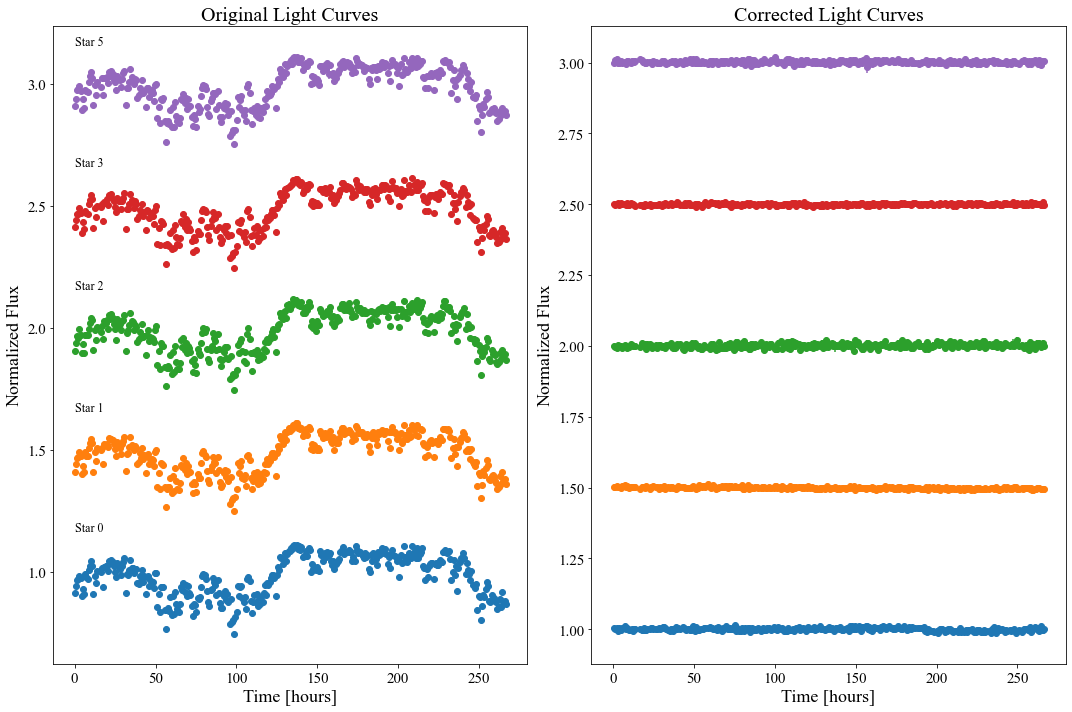

In [4]:
# Now that we have our reference light curve, we can divide all the light curves by it to normalize them by the reference curve
# This should account for the brightness variations in the images

# Let's take a look at a few of our good ones 

In [5]:
# You could use a widget again if you'd like to look closer at your newly corrected light curves 

def plot_lc(index):
    index = good_index[index]

    flux = phot[index].flux
    flux_err = phot[index].flux_err
    corrected_flux = np.copy(flux)/reference_lc
    corrected_flux_err = np.copy(flux_err)/reference_lc
    
    plt.figure(figsize=(10,5))
    plt.errorbar(phot[index].time,corrected_flux,yerr=corrected_flux_err,fmt='o')
    plt.xlabel('Time [hours]',fontsize=18)
    plt.ylabel('Normalized Flux',fontsize=18)
    plt.title(f'Light Curve of Star {index}',fontsize=20)
    plt.tick_params(labelsize=15);

w = widgets.IntSlider()
widgets.interact(plot_lc,index=w)


interactive(children=(IntSlider(value=0, description='index'), Output()), _dom_classes=('widget-interact',))

<function __main__.plot_lc(index)>

In [6]:
# If things look good to you, save the corrected light curves to a file
# In the next notebook we'll use this to generate the light curve of our exoplanet 

np.savetxt('Photometry/template_light_curve.txt',reference_lc)